# Exercise 41 – Derivatives of a polynomial with autograd

**Week 8 · Automatic differentiation**

PyTorch can differentiate any expression built from tensors. Here we use
`torch.autograd.grad` to get the first and second derivative of

$$f(x) = -\tfrac{3}{2}x^3 - x^2 + 2x + 2$$

and check them against the analytic derivatives at a few test points.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.plotting import setup_axes


def f(x):
    return -1.5 * x**3 - x**2 + 2 * x + 2


def df_exact(x):
    return -4.5 * x**2 - 2 * x + 2


def d2f_exact(x):
    return -9 * x - 2

`create_graph=True` keeps the graph of the first derivative so that it can be
differentiated once more.

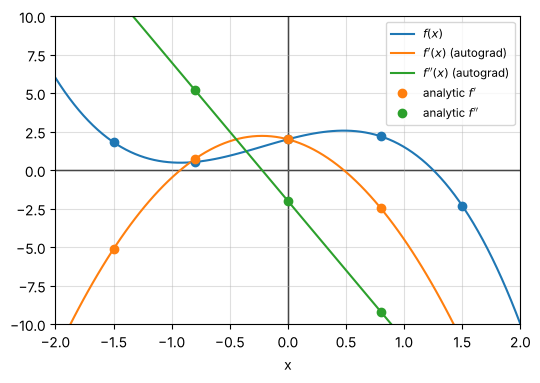

In [2]:
xs = torch.linspace(-2, 2, 100, requires_grad=True)
ys = f(xs)
dfdx = torch.autograd.grad(ys, xs, torch.ones_like(xs), create_graph=True)[0]
d2fdx2 = torch.autograd.grad(dfdx, xs, torch.ones_like(xs))[0]

test_points = torch.tensor([-1.5, -0.8, 0.0, 0.8, 1.5])

fig, ax = plt.subplots(figsize=(6, 4))
with torch.no_grad():
    ax.plot(xs, ys, label="$f(x)$")
    ax.plot(xs, dfdx, label="$f'(x)$ (autograd)")
    ax.plot(xs, d2fdx2, label="$f''(x)$ (autograd)")
ax.plot(test_points, f(test_points), "o", color="C0")
ax.plot(test_points, df_exact(test_points), "o", color="C1", label="analytic $f'$")
ax.plot(test_points, d2f_exact(test_points), "o", color="C2", label="analytic $f''$")
setup_axes(ax, xlim=(-2, 2), ylim=(-10, 10), ylabel="")
ax.legend(fontsize="small")
plt.show()

The autograd curves pass through the analytic values at every test point:

In [3]:
x = test_points.clone().requires_grad_(True)
d1 = torch.autograd.grad(f(x).sum(), x, create_graph=True)[0]
d2 = torch.autograd.grad(d1.sum(), x)[0]
print("max |f' error| :", (d1 - df_exact(test_points)).abs().max().item())
print("max |f''error| :", (d2 - d2f_exact(test_points)).abs().max().item())

max |f' error| : 1.1920928955078125e-07
max |f''error| : 0.0
